In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install catboost

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 MB 11.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import random
import math
import warnings
warnings.filterwarnings('ignore')

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, accuracy_score, log_loss, f1_score, roc_curve, accuracy_score, roc_auc_score, precision_recall_curve, plot_roc_curve
from sklearn.model_selection import RepeatedKFold, cross_val_score, StratifiedKFold, KFold, train_test_split, StratifiedShuffleSplit, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

# regressor
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
from lightgbm import LGBMRegressor

# classifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

import torch

In [ ]:
SEED = 42
deterministic = True

def seed_fixed(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic: # cudnn's random seed fixed (slow learning rate)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_fixed(SEED)

In [ ]:
#data_dir = '/kaggle/input/lg-data/'
data_dir = '/content/drive/MyDrive/LG_Aimers/'
submission = pd.read_csv(data_dir + 'sample_submission.csv')
test = pd.read_csv(data_dir + 'test.csv')
train = pd.read_csv(data_dir + 'train.csv')

In [ ]:
train['LINE'].value_counts()

T100304    175
T100306    174
T050304     78
T010306     70
T010305     59
T050307     42
Name: LINE, dtype: int64

In [ ]:
train[train['LINE'] == 'T100304']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
22,TRAIN_022,0,0.517719,2022-06-14 8:53,T100304,T_31,2.0,102.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,TRAIN_023,0,0.519090,2022-06-14 9:01,T100304,T_31,2.0,102.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25,TRAIN_025,1,0.529362,2022-06-19 9:11,T100304,T_31,2.0,97.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,TRAIN_029,1,0.532405,2022-06-19 23:31,T100304,T_31,2.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37,TRAIN_037,1,0.533110,2022-06-22 3:47,T100304,T_31,2.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
561,TRAIN_561,0,0.522148,2022-09-02 18:15,T100304,T_31,2.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
569,TRAIN_569,1,0.530533,2022-09-03 18:32,T100304,O_31,4.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
571,TRAIN_571,1,0.525916,2022-09-03 18:48,T100304,O_31,4.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592,TRAIN_592,1,0.528349,2022-09-08 14:22,T100304,T_31,2.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train[train['LINE'] == 'T100306']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
26,TRAIN_026,1,0.531992,2022-06-19 9:20,T100306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,TRAIN_030,1,0.528646,2022-06-19 23:39,T100306,T_31,2.0,88.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,TRAIN_036,1,0.529633,2022-06-22 3:39,T100306,T_31,2.0,91.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,TRAIN_042,1,0.530965,2022-06-23 3:39,T100306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,TRAIN_043,1,0.529498,2022-06-23 6:28,T100306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,TRAIN_589,1,0.529510,2022-09-06 18:00,T100306,T_31,1.0,94.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590,TRAIN_590,1,0.529948,2022-09-07 1:01,T100306,T_31,1.0,89.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,TRAIN_591,1,0.529308,2022-09-07 1:09,T100306,T_31,1.0,87.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
593,TRAIN_593,1,0.526546,2022-09-08 14:30,T100306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train[train['LINE'] == 'T050304']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
0,TRAIN_000,1,0.533433,2022-06-13 5:14,T050304,A_31,NaN,NaN,NaN,NaN,...,39.34,40.89,32.56,34.09,77.77,NaN,NaN,NaN,NaN,NaN
2,TRAIN_002,1,0.531267,2022-06-13 5:30,T050304,A_31,NaN,NaN,NaN,NaN,...,39.19,36.65,42.47,36.53,78.35,NaN,NaN,NaN,NaN,NaN
4,TRAIN_004,1,0.531590,2022-06-13 5:47,T050304,A_31,NaN,NaN,NaN,NaN,...,38.70,41.89,46.93,33.09,76.97,NaN,NaN,NaN,NaN,NaN
6,TRAIN_006,1,0.533665,2022-06-13 6:03,T050304,A_31,NaN,NaN,NaN,NaN,...,32.50,41.42,38.36,30.83,76.93,NaN,NaN,NaN,NaN,NaN
8,TRAIN_008,1,0.531821,2022-06-13 6:19,T050304,A_31,NaN,NaN,NaN,NaN,...,42.25,43.17,55.60,33.26,78.50,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,TRAIN_581,0,0.523465,2022-09-05 8:18,T050304,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
582,TRAIN_582,0,0.522233,2022-09-05 8:26,T050304,A_31,NaN,NaN,NaN,NaN,...,50.88,53.23,52.44,56.28,66.83,1.0,NaN,NaN,NaN,NaN
583,TRAIN_583,0,0.522340,2022-09-05 8:34,T050304,A_31,NaN,NaN,NaN,NaN,...,51.71,59.64,54.61,57.05,63.18,1.0,NaN,NaN,NaN,NaN
594,TRAIN_594,0,0.524022,2022-09-08 22:38,T050304,A_31,NaN,NaN,NaN,NaN,...,49.47,53.07,50.89,55.10,66.49,1.0,NaN,NaN,NaN,NaN


In [ ]:
train[train['LINE'] == 'T050307']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
1,TRAIN_001,2,0.541819,2022-06-13 5:22,T050307,A_31,NaN,NaN,NaN,NaN,...,38.89,42.82,43.92,35.34,72.55,NaN,NaN,NaN,NaN,NaN
3,TRAIN_003,2,0.537325,2022-06-13 5:39,T050307,A_31,NaN,NaN,NaN,NaN,...,37.74,39.17,52.17,30.58,71.78,NaN,NaN,NaN,NaN,NaN
5,TRAIN_005,2,0.537833,2022-06-13 5:55,T050307,A_31,NaN,NaN,NaN,NaN,...,38.16,51.25,56.01,37.41,71.37,NaN,NaN,NaN,NaN,NaN
7,TRAIN_007,2,0.540003,2022-06-13 6:11,T050307,A_31,NaN,NaN,NaN,NaN,...,39.00,35.95,59.51,30.49,72.77,NaN,NaN,NaN,NaN,NaN
9,TRAIN_009,2,0.538049,2022-06-13 6:28,T050307,A_31,NaN,NaN,NaN,NaN,...,34.40,35.88,50.36,38.45,71.42,NaN,NaN,NaN,NaN,NaN
11,TRAIN_011,2,0.539149,2022-06-13 6:44,T050307,A_31,NaN,NaN,NaN,NaN,...,39.16,35.49,52.27,31.45,72.46,NaN,NaN,NaN,NaN,NaN
13,TRAIN_013,2,0.538508,2022-06-13 7:00,T050307,A_31,NaN,NaN,NaN,NaN,...,40.42,34.33,41.98,40.34,72.77,NaN,NaN,NaN,NaN,NaN
15,TRAIN_015,2,0.539254,2022-06-13 7:17,T050307,A_31,NaN,NaN,NaN,NaN,...,38.03,44.53,41.54,37.20,72.46,NaN,NaN,NaN,NaN,NaN
17,TRAIN_017,2,0.538854,2022-06-13 7:33,T050307,A_31,NaN,NaN,NaN,NaN,...,33.16,33.26,55.97,35.17,71.40,NaN,NaN,NaN,NaN,NaN
19,TRAIN_019,2,0.539235,2022-06-13 7:49,T050307,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train[train['LINE'] == 'T010305']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
28,TRAIN_028,0,0.521249,2022-06-19 20:26,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33,TRAIN_033,1,0.526656,2022-06-21 7:14,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,TRAIN_039,1,0.531583,2022-06-22 4:45,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,TRAIN_040,1,0.530829,2022-06-22 12:26,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,TRAIN_041,1,0.528270,2022-06-22 12:34,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48,TRAIN_048,1,0.533273,2022-06-23 15:50,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
52,TRAIN_052,2,0.555514,2022-06-24 4:13,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
57,TRAIN_057,2,0.535741,2022-06-24 21:38,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,TRAIN_058,2,0.537122,2022-06-24 21:46,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,TRAIN_059,2,0.536859,2022-06-24 22:39,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train[train['LINE'] == 'T010306']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
27,TRAIN_027,2,0.540002,2022-06-19 20:18,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,TRAIN_031,2,0.536206,2022-06-20 21:55,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,TRAIN_032,2,0.548592,2022-06-21 7:06,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38,TRAIN_038,2,0.536616,2022-06-22 4:37,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,TRAIN_047,1,0.533230,2022-06-23 15:42,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,TRAIN_479,1,0.534716,2022-08-16 15:28,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
501,TRAIN_501,1,0.533079,2022-08-19 15:58,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
523,TRAIN_523,1,0.534640,2022-08-21 10:39,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
531,TRAIN_531,2,0.560317,2022-08-22 15:38,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train['PRODUCT_CODE'].value_counts()

T_31    343
A_31    249
O_31      6
Name: PRODUCT_CODE, dtype: int64

In [ ]:
train[train['PRODUCT_CODE'] == 'T_31']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
22,TRAIN_022,0,0.517719,2022-06-14 8:53,T100304,T_31,2.0,102.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,TRAIN_023,0,0.519090,2022-06-14 9:01,T100304,T_31,2.0,102.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25,TRAIN_025,1,0.529362,2022-06-19 9:11,T100304,T_31,2.0,97.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,TRAIN_026,1,0.531992,2022-06-19 9:20,T100306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,TRAIN_029,1,0.532405,2022-06-19 23:31,T100304,T_31,2.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,TRAIN_589,1,0.529510,2022-09-06 18:00,T100306,T_31,1.0,94.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590,TRAIN_590,1,0.529948,2022-09-07 1:01,T100306,T_31,1.0,89.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,TRAIN_591,1,0.529308,2022-09-07 1:09,T100306,T_31,1.0,87.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592,TRAIN_592,1,0.528349,2022-09-08 14:22,T100304,T_31,2.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
train[train['PRODUCT_CODE'] == 'A_31']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
0,TRAIN_000,1,0.533433,2022-06-13 5:14,T050304,A_31,NaN,NaN,NaN,NaN,...,39.34,40.89,32.56,34.09,77.77,NaN,NaN,NaN,NaN,NaN
1,TRAIN_001,2,0.541819,2022-06-13 5:22,T050307,A_31,NaN,NaN,NaN,NaN,...,38.89,42.82,43.92,35.34,72.55,NaN,NaN,NaN,NaN,NaN
2,TRAIN_002,1,0.531267,2022-06-13 5:30,T050304,A_31,NaN,NaN,NaN,NaN,...,39.19,36.65,42.47,36.53,78.35,NaN,NaN,NaN,NaN,NaN
3,TRAIN_003,2,0.537325,2022-06-13 5:39,T050307,A_31,NaN,NaN,NaN,NaN,...,37.74,39.17,52.17,30.58,71.78,NaN,NaN,NaN,NaN,NaN
4,TRAIN_004,1,0.531590,2022-06-13 5:47,T050304,A_31,NaN,NaN,NaN,NaN,...,38.70,41.89,46.93,33.09,76.97,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,TRAIN_583,0,0.522340,2022-09-05 8:34,T050304,A_31,NaN,NaN,NaN,NaN,...,51.71,59.64,54.61,57.05,63.18,1.0,NaN,NaN,NaN,NaN
584,TRAIN_584,0,0.519519,2022-09-05 11:09,T010305,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
585,TRAIN_585,0,0.515214,2022-09-05 11:17,T010306,A_31,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
594,TRAIN_594,0,0.524022,2022-09-08 22:38,T050304,A_31,NaN,NaN,NaN,NaN,...,49.47,53.07,50.89,55.10,66.49,1.0,NaN,NaN,NaN,NaN


In [ ]:
train[train['PRODUCT_CODE'] == 'O_31']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875
569,TRAIN_569,1,0.530533,2022-09-03 18:32,T100304,O_31,4.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
570,TRAIN_570,2,0.534951,2022-09-03 18:40,T100306,O_31,6.0,90.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
571,TRAIN_571,1,0.525916,2022-09-03 18:48,T100304,O_31,4.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
572,TRAIN_572,2,0.535205,2022-09-03 18:56,T100306,O_31,6.0,89.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
596,TRAIN_596,1,0.531375,2022-09-08 14:38,T100304,O_31,40.0,94.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
597,TRAIN_597,1,0.533702,2022-09-08 14:46,T100306,O_31,21.0,87.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


PRODUCT_ID : 제품의 고유 ID

Y_Class : 제품 품질 상태(Target)
- 0 : 적정 기준 미달 (부적합)
- 1 : 적합
- 2 : 적정 기준 초과 (부적합)

Y_Quality : 제품 품질 관련 정량적 수치

TIMESTAMP : 제품이 공정에 들어간 시각

LINE : 제품이 들어간 공정 LINE 종류 ('T050304', 'T050307', 'T100304', 'T100306', 'T010306', 'T010305' 존재)

PRODUCT_CODE : 제품의 CODE 번호 ('A_31', 'T_31', 'O_31' 존재)

X_1 ~ X_2875 : 공정 과정에서 추출되어 비식별화된 변수

# 분석

In [ ]:
def plot(data, columns):
    for idx, column in enumerate(columns):
        plt.plot(data[column][data['Y_Class'] == 0], alpha = 0.8, color = 'blue')
        plt.plot(data[column][data['Y_Class'] == 1], alpha = 0.8, color = 'green')
        plt.plot(data[column][data['Y_Class'] == 2], alpha = 0.8, color = 'red')
        plt.title(str(column))
        plt.show()

In [ ]:
def add_boundary_plot(data, columns, target_list):

    for idx, column in enumerate(columns):

        data[column] = data[column].dropna(axis = 0)

        fig, axes = plt.subplots(1, len(target_list))
        fig.set_figwidth(12)
        fig.set_figheight(12)

        for i, target in enumerate(target_list):

            q1, q3 = np.percentile(data[column][data['Y_Class'] == target], [25, 75])
            iqr = q3 - q1
            lower_boundary = q1 - (iqr * 1.5)
            upper_boundary = q3 + (iqr * 1.5)

            #axes[i].plot(data[column][data['Y_Class'] == target], alpha = 0.8, color = 'green')
            sns.scatterplot(data = data[column][data['Y_Class'] == target], ax = axes[i])
            axes[i].set_title(str(column) + ' of (Y_Class=' + str(target) + ')')

            # boundary line
            axes[i].hlines(y = lower_boundary, xmin = 0, xmax = data.shape[0], color = 'red')
            axes[i].hlines(y = upper_boundary, xmin = 0, xmax = data.shape[0], color = 'red')

        plt.show()

In [ ]:
#add_boundary_plot(train[combination_dict[478]+['Y_Class']], combination_dict[478], [0, 1, 2])
#add_boundary_plot(train, train.columns[train.columns.str.contains('X_')].tolist(), [0, 1, 2])

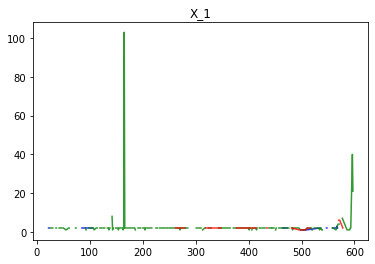

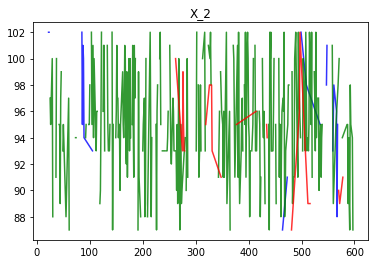

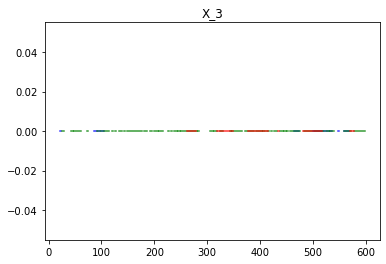

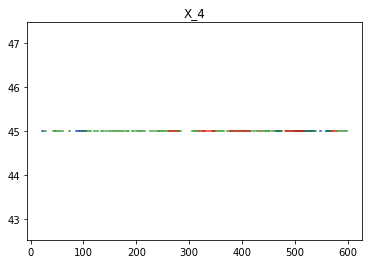

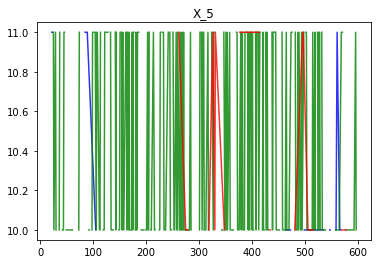

...

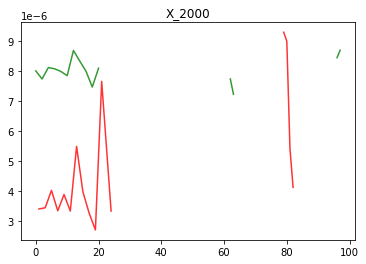

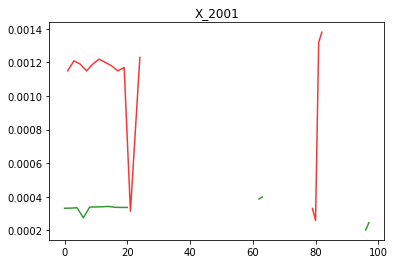

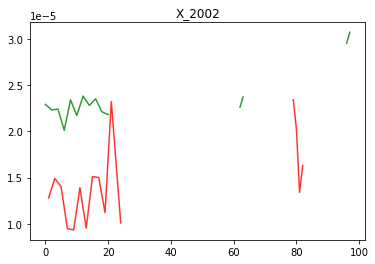

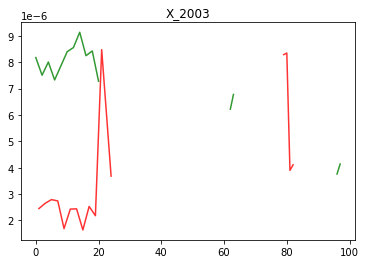

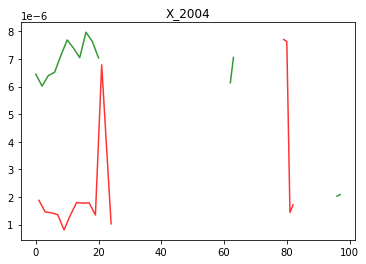

In [ ]:
plot(train, train.columns[train.columns.str.contains('X')].tolist())

In [ ]:
train['LINE'].value_counts()

T100304    175
T100306    174
T050304     78
T010306     70
T010305     59
T050307     42
Name: LINE, dtype: int64

In [ ]:
# 0.

train['PROCESS'] = train['LINE'].str[:4]
test['PROCESS'] = test['LINE'].str[:4]

train['LINE'] = train['LINE'].str[4:]
test['LINE'] = test['LINE'].str[4:]

In [ ]:
train.loc[train['PRODUCT_CODE'] == 'O_31']

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2867,X_2868,X_2869,X_2870,X_2871,X_2872,X_2873,X_2874,X_2875,PROCESS
569,TRAIN_569,1,0.530533,2022-09-03 18:32,304,O_31,4.0,98.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
570,TRAIN_570,2,0.534951,2022-09-03 18:40,306,O_31,6.0,90.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
571,TRAIN_571,1,0.525916,2022-09-03 18:48,304,O_31,4.0,100.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
572,TRAIN_572,2,0.535205,2022-09-03 18:56,306,O_31,6.0,89.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
596,TRAIN_596,1,0.531375,2022-09-08 14:38,304,O_31,40.0,94.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
597,TRAIN_597,1,0.533702,2022-09-08 14:46,306,O_31,21.0,87.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100


In [ ]:
# drop all null
drop_index = train.isnull().sum()[(train.isnull().sum() == train.shape[0])].index.tolist() #| (test.isnull().sum() == test.shape[0])
train = train.drop(drop_index, axis = 1)
test = test.drop(drop_index, axis = 1)

In [ ]:
# for column in train.columns:
#     if len(train[column].value_counts()) < 2:
#         train.drop(column, axis = 1, inplace = True)
#         test.drop(column, axis = 1, inplace = True)

In [ ]:
# 1.

null_count_df = pd.DataFrame(train[train.columns[train.columns.str.contains('X')]].isna().sum()).rename(columns = {0:'count'})
count_values = null_count_df['count'].value_counts().index.tolist()

combination_dict = dict()
for count in count_values:
    combination_dict[count] = null_count_df.loc[null_count_df['count'] == count].index.tolist()

In [ ]:
# a = combination_dict[478] + ['PROCESS']

# temp = train[a].dropna()
# temp.PROCESS.value_counts()

X_ 값들은 각 공정을 거친 후 각 Check Point에서 확인된 값들임을 유추할 수 있다.

In [ ]:
# oulier detection

def detected_outlier(train, columns, option = True):

    out_ = []
    for column in train.drop(['Y_Class'], axis = 1).columns:
        if column not in columns:
            out_.append(column)

    out_temp = train[out_]
    in_temp = train[columns + ['Y_Class']]

    target_list = [0, 1, 2]

    for target in target_list:
        for column in columns:
            column_ = [column] + ['Y_Class']
            temp = train[column_].dropna()
            temp = temp[column][temp['Y_Class'] == target]

            if len(temp) == 0:
                continue

            q1, q3 = np.percentile(temp, [25, 75])
            iqr = q3 - q1
            lower_boundary = q1 - (iqr * 1.5)
            upper_boundary = q3 + (iqr * 1.5)

            most_freq = train[column].value_counts(dropna = True).idxmax()

            in_temp[column][(in_temp['Y_Class'] == target) & (in_temp[column] > upper_boundary) | (in_temp[column] < lower_boundary)] = most_freq

    return in_temp[columns]

# for n in combination_dict:
#     combination = combination_dict[n]
#     in_temp = detected_outlier(train, combination)
#     train[combination_dict[n]] = in_temp

In [ ]:
# 2.

def find_correlated_combinations(train, column_list):
    corr_matrix = train.corr()

    correlated_combinations_ = list(['fff'])
    for i, col1 in enumerate(column_list):
        if col1 in correlated_combinations_[-1]:
            continue
        correlated_combinations = list()
        for col2 in column_list:
            corr_value = corr_matrix.loc[col1, col2]
            if abs(corr_value) >= 0.67 and column_list[i] == col2:
                correlated_combinations.append(col2)
                i += 1

        correlated_combinations_.append(correlated_combinations)
    correlated_combinations_ = correlated_combinations_[1:]
    return correlated_combinations_

In [ ]:
# augmentation
def augmentation(train, columns):
    train_copy = train.copy()
    ctl1 = train_copy.sample(train_copy.shape[0], random_state = SEED).reset_index(drop = True)
    ctl2 = train_copy.sample(train_copy.shape[0], random_state = SEED + SEED).reset_index(drop = True)
    train_copy[columns] = (train_copy[columns].values + ctl1[columns].values) - ctl2[columns].values
    return train_copy

# pca
def pca_transform(train, test, columns, n_components):
    pca = PCA(n_components = n_components, random_state = SEED)
    pca.fit(train[columns])
    train_transformed = pca.transform(train[columns])
    test_transformed = pca.transform(test[columns])

    train = train.drop(columns, axis = 1)
    test = test.drop(columns, axis = 1)

    train_transformed_df = pd.DataFrame(train_transformed, columns = ['{}_{}_pca{}'.format(columns[0], columns[-1], n) for n in range(n_components)])
    test_transformed_df = pd.DataFrame(test_transformed, columns = ['{}_{}_pca{}'.format(columns[0], columns[-1], n) for n in range(n_components)])

    train = pd.concat([train, train_transformed_df], axis = 1)
    test = pd.concat([test, test_transformed_df], axis = 1)

    return train, test

# rank gauss
def rank_gauss(train, test, columns):
    for column in columns:
        transformer = QuantileTransformer(n_quantiles = 100, random_state = SEED, output_distribution = 'normal')
        transformer.fit(train[:train.shape[0]][column].values.reshape(-1,1))
        train[column] = transformer.transform(train[column].values.reshape(-1,1))
        test[column] = transformer.transform(test[column].values.reshape(-1,1))
    return train, test

def standard_scaler(train, test, columns):
    for column in columns:
        scaler = StandardScaler()
        scaler.fit(train[:train.shape[0]][column].values.reshape(-1,1))
        train[column] = scaler.transform(train[column].values.reshape(-1,1))
        test[column] = scaler.transform(test[column].values.reshape(-1,1))
    return train, test

In [ ]:
def fillna_sampling(data):
    data_copy = data.copy()
    columns = data.columns[data.columns.str.contains('X_')].tolist()

    for line in data_copy.LINE.value_counts().index.tolist():
        for code in data_copy.PRODUCT_CODE.value_counts().index.tolist():
            for column in columns:
                index_list = data_copy[(data_copy[column].isna()) & (data_copy['LINE'] == line) & (data_copy['PRODUCT_CODE'] == code)].index
                #print(index_list)
                temp = data_copy[(data_copy['LINE'] == line) & (data_copy['PRODUCT_CODE'] == code)][column].drop(index_list, axis = 0)
                #print(temp)
                if temp.shape[0] == 0:
                    continue

                #samples = temp.sample(len(index_list), replace = True)
                #samples = np.mean(temp)
                samples = np.median(temp)
                #print(pd.DataFrame(samples).sort_index(ascending = True))
                #print(train.loc[(train[column].isna()) & (train['Y_Class'] == target), column])

                data.loc[(data[column].isna()) & (data_copy['LINE'] == line) & (data_copy['PRODUCT_CODE'] == code), column] = samples
    return data

In [ ]:
def line_fillna(data):
    data_copy = data.copy()
    columns = data.columns[data.columns.str.contains('X_')].tolist()

    for line in data_copy.LINE.value_counts().index.tolist():
        for column in columns:
            index_list = data_copy[(data_copy[column].isna()) & (data_copy['LINE'] == line)].index
            temp = data_copy[data_copy['LINE'] == line][column].drop(index_list, axis = 0)
            if temp.shape[0] == 0:
                continue

            samples = np.mean(temp)

            data.loc[(data[column].isna()) & (data_copy['LINE'] == line), column] = samples
    return data

def productcode_fillna(data):
    data_copy = data.copy()
    columns = data.columns[data.columns.str.contains('X_')].tolist()

    for code in data_copy.PRODUCT_CODE.value_counts().index.tolist():
        for column in columns:
            index_list = data_copy[(data_copy[column].isna()) & (data_copy['PRODUCT_CODE'] == code)].index
            temp = data_copy[data_copy['PRODUCT_CODE'] == code][column].drop(index_list, axis = 0)
            if temp.shape[0] == 0:
                continue

            samples = np.mean(temp)

            data.loc[(data[column].isna()) & (data_copy['PRODUCT_CODE'] == code), column] = samples
    return data

def process_fillna(data):
    data_copy = data.copy()
    columns = data.columns[data.columns.str.contains('X_')].tolist()

    for process in data_copy.PROCESS.value_counts().index.tolist():
        for column in columns:
            index_list = data_copy[(data_copy[column].isna()) & (data_copy['PROCESS'] == process)].index
            temp = data_copy[data_copy['PROCESS'] == process][column].drop(index_list, axis = 0)
            if temp.shape[0] == 0:
                continue

            samples = np.mean(temp)

            data.loc[(data[column].isna()) & (data_copy['PROCESS'] == process), column] = samples
    return data

In [ ]:
train = fillna_sampling(train)
test = fillna_sampling(test)

In [ ]:
train

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,...,X_2863,X_2864,X_2865,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,PROCESS
0,TRAIN_000,1,0.533433,2022-06-13 5:14,304,A_31,NaN,NaN,NaN,NaN,...,383.0,368.296296,353.0,39.340000,40.890000,32.560000,34.090000,77.77000,1.0,T050
1,TRAIN_001,2,0.541819,2022-06-13 5:22,307,A_31,NaN,NaN,NaN,NaN,...,383.0,367.735849,353.0,38.890000,42.820000,43.920000,35.340000,72.55000,1.0,T050
2,TRAIN_002,1,0.531267,2022-06-13 5:30,304,A_31,NaN,NaN,NaN,NaN,...,383.0,367.320755,353.0,39.190000,36.650000,42.470000,36.530000,78.35000,1.0,T050
3,TRAIN_003,2,0.537325,2022-06-13 5:39,307,A_31,NaN,NaN,NaN,NaN,...,384.0,369.188679,353.0,37.740000,39.170000,52.170000,30.580000,71.78000,1.0,T050
4,TRAIN_004,1,0.531590,2022-06-13 5:47,304,A_31,NaN,NaN,NaN,NaN,...,383.0,367.351852,352.0,38.700000,41.890000,46.930000,33.090000,76.97000,1.0,T050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,TRAIN_593,1,0.526546,2022-09-08 14:30,306,T_31,2.0,95.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
594,TRAIN_594,0,0.524022,2022-09-08 22:38,304,A_31,NaN,NaN,NaN,NaN,...,384.0,369.811321,353.0,49.470000,53.070000,50.890000,55.100000,66.49000,1.0,T050
595,TRAIN_595,0,0.521289,2022-09-08 22:47,304,A_31,NaN,NaN,NaN,NaN,...,383.0,367.018868,352.0,51.557313,54.230149,48.665224,52.332537,66.68597,1.0,T050
596,TRAIN_596,1,0.531375,2022-09-08 14:38,304,O_31,40.0,94.0,0.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100


In [ ]:
test

,PRODUCT_ID,TIMESTAMP,LINE,PRODUCT_CODE,X_1,X_2,X_3,X_4,X_5,X_6,...,X_2863,X_2864,X_2865,X_2866,X_2867,X_2868,X_2869,X_2870,X_2871,PROCESS
0,TEST_000,2022-09-09 2:01,306,T_31,2.0,94.0,0.0,45.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
1,TEST_001,2022-09-09 2:09,304,T_31,2.0,93.0,0.0,45.0,11.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
2,TEST_002,2022-09-09 8:42,304,T_31,2.0,95.0,0.0,45.0,11.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
3,TEST_003,2022-09-09 10:56,305,A_31,NaN,NaN,NaN,NaN,NaN,NaN,...,467.0,444.192308,423.0,NaN,NaN,NaN,NaN,NaN,NaN,T010
4,TEST_004,2022-09-09 11:04,306,A_31,NaN,NaN,NaN,NaN,NaN,NaN,...,465.0,443.211539,423.0,NaN,NaN,NaN,NaN,NaN,NaN,T010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
305,TEST_305,2022-11-05 11:18,306,T_31,2.0,91.0,0.0,45.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
306,TEST_306,2022-11-05 16:39,304,T_31,2.0,96.0,0.0,45.0,11.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
307,TEST_307,2022-11-05 16:47,306,T_31,2.0,91.0,0.0,45.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100
308,TEST_308,2022-11-05 20:53,306,T_31,2.0,95.0,0.0,45.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,T100


In [ ]:
np.sum(train.isnull().sum()[train.isnull().sum() > 0].values)

In [ ]:
np.sum(train.isnull().sum()[train.isnull().sum() > 0].values)

In [ ]:
train[train['Y_Class'] == 0].isnull().sum().sum() / (train[train['Y_Class'] == 0].shape[0] * 100), train[train['Y_Class'] == 1].isnull().sum().sum() / (train[train['Y_Class'] == 1].shape[0] * 100), train[train['Y_Class'] == 2].isnull().sum().sum() / (train[train['Y_Class'] == 2].shape[0] * 100)

In [ ]:
for line in train['LINE'].value_counts().index.tolist():
  print(train[train['LINE'] == line].isnull().sum().sum() / (train[train['LINE'] == line].shape[0] * 100))

In [ ]:
for code in train['PRODUCT_CODE'].value_counts().index.tolist():
  print(train[train['PRODUCT_CODE'] == code].isnull().sum().sum() / (train[train['PRODUCT_CODE'] == code].shape[0] * 100))

In [ ]:
for process in train['PROCESS'].value_counts().index.tolist():
  print(train[train['PROCESS'] == process].isnull().sum().sum() / (train[train['PROCESS'] == process].shape[0] * 100))

In [ ]:
#train_aug = augmentation(train, train.columns[train.columns.str.contains('X_')])
#train = pd.concat([train, train_aug])

In [ ]:
#train, test = rank_gauss(train, test, train.columns[train.columns.str.contains('X')].tolist())

#train, test = standard_scaler(train, test, train.columns[train.columns.str.contains('X')].tolist())

In [ ]:
def corr_pca_transform(train, test, combination_dict):

    for n in combination_dict:
        combination = combination_dict[n]
        train_copy = train.copy()
        temp = find_correlated_combinations(train_copy[combination], combination)

        test_copy = test.copy()

        # pca groupby continue process
        for tp in temp:
            if len(tp) > 1:
                if len(tp) % 2 == 0:
                    train_copy[tp] = train_copy[tp].fillna(-999)
                    test_copy[tp] = test_copy[tp].fillna(-999)
                    train_copy, test_copy = pca_transform(train_copy, test_copy, tp, len(tp)//2)
                else:
                    train_copy[tp] = train_copy[tp].fillna(-999)
                    test_copy[tp] = test_copy[tp].fillna(-999)
                    train_copy, test_copy = pca_transform(train_copy, test_copy, tp, math.floor(len(tp)//2))
            else:
                continue

    return train_copy, test_copy

In [ ]:
def corr_pca_transform(train, test, combination_dict):

    for n in combination_dict:
        combination = combination_dict[n]
        temp = find_correlated_combinations(train[combination], combination)
        #print(temp)

        # pca groupby continue process
        for tp in temp:
            if len(tp) > 1:
                if len(tp) % 2 == 0:
                    train[tp] = train[tp].fillna(-999)
                    test[tp] = test[tp].fillna(-999)
                    train, test = pca_transform(train, test, tp, len(tp)//2)
                else:
                    train[tp] = train[tp].fillna(-999)
                    test[tp] = test[tp].fillna(-999)
                    train, test = pca_transform(train, test, tp, math.floor(len(tp)//2))
            else:
                continue

    return train, test

train, test = corr_pca_transform(train, test, combination_dict)

KeyboardInterrupt: ignored

In [ ]:
train

In [ ]:
def agg_func(data, columns, groupcolumns):
    data = data.fillna(0)
    agg_data_x = pd.pivot_table(data, values = columns, index=groupcolumns,
                         aggfunc=['min','max','mean', 'std']
                        ).reset_index()
    agg_columns = groupcolumns+[agg+'_'+name for agg,name in agg_data_x.columns][3:]
    agg_data_x.columns = agg_columns
    return agg_data_x

def mean_func(data, columns):
    data = data.fillna(0)
    first_temp = data[columns[0]]
    for idx in range(1, len(columns)):
        first_temp += data[columns[idx]]

    mean_data_x = first_temp / len(columns)
    mean_data_x = pd.DataFrame(mean_data_x, columns = [columns[0]+'_'+columns[-1]+'_mean'])
    return mean_data_x

def corr_agg_func(train, test, combination_dict):

    for n in combination_dict:
        combination = combination_dict[n]
        temp = find_correlated_combinations(train[combination], combination)

        # pca groupby continue process
        for tp in temp:
            if len(tp) > 1:
                agg_train_x = agg_func(train, tp, ['LINE', 'PRODUCT_CODE', 'PROCESS'])
                agg_test_x = agg_func(test, tp, ['LINE', 'PRODUCT_CODE', 'PROCESS'])
                train = pd.merge(train, agg_train_x, how = 'left', left_on = ['LINE', 'PRODUCT_CODE', 'PROCESS'], right_on =  ['LINE', 'PRODUCT_CODE', 'PROCESS'])
                test = pd.merge(test, agg_test_x, how = 'left', left_on = ['LINE', 'PRODUCT_CODE', 'PROCESS'], right_on =  ['LINE', 'PRODUCT_CODE', 'PROCESS'])
                #mean_train_x = mean_func(train, tp)
                #mean_test_x = mean_func(test, tp)
                #train = pd.concat([train, mean_train_x], axis = 1)
                #test = pd.concat([test, mean_test_x], axis = 1)
            else:
                continue

    return train, test

In [ ]:
train, test = corr_agg_func(train, test, combination_dict)

In [ ]:
train

,PRODUCT_ID,Y_Class,Y_Quality,TIMESTAMP,X_1,X_2,X_3,X_4,X_5,X_6,...,LINE__0,LINE__1,LINE__2,LINE__3,PRODUCT_CODE__0,PRODUCT_CODE__1,PRODUCT_CODE__2,PROCESS__0,PROCESS__1,PROCESS__2
0,TRAIN_000,1,0.533433,2022-06-13 5:14,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,1,0,0,0,1,0,0,0,1,0
1,TRAIN_001,2,0.541819,2022-06-13 5:22,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,0,0,0,1,1,0,0,0,1,0
2,TRAIN_002,1,0.531267,2022-06-13 5:30,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,1,0,0,0,1,0,0,0,1,0
3,TRAIN_003,2,0.537325,2022-06-13 5:39,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,0,0,0,1,1,0,0,0,1,0
4,TRAIN_004,1,0.531590,2022-06-13 5:47,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,1,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
593,TRAIN_593,1,0.526546,2022-09-08 14:30,2.0,95.0,0.0,45.0,10.0,0.0,...,0,0,1,0,0,0,1,0,0,1
594,TRAIN_594,0,0.524022,2022-09-08 22:38,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,1,0,0,0,1,0,0,0,1,0
595,TRAIN_595,0,0.521289,2022-09-08 22:47,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,...,1,0,0,0,1,0,0,0,1,0
596,TRAIN_596,1,0.531375,2022-09-08 14:38,40.0,94.0,0.0,45.0,11.0,0.0,...,1,0,0,0,0,1,0,0,0,1


In [ ]:
train = train.fillna(-999)
test = test.fillna(-999)

In [ ]:
print(len(train['LINE'].value_counts()), len(test['LINE'].value_counts()))
print(len(train['PRODUCT_CODE'].value_counts()), len(test['PRODUCT_CODE'].value_counts()))
print(len(train['PROCESS'].value_counts()), len(test['PROCESS'].value_counts()))

4 4
3 3
3 3


In [ ]:
train.shape, test.shape

((598, 2800), (310, 2798))

In [ ]:
encoding_columns = ['LINE', 'PRODUCT_CODE', 'PROCESS']

for col in encoding_columns:
    encoder = LabelEncoder()
    encoder.fit(train[col])
    train[col] = encoder.transform(train[col])

    for label in np.unique(test[col]):
        if label not in encoder.classes_:
            encoder.classes_ = np.append(encoder.classes_, label)

    test[col] = encoder.transform(test[col])

In [ ]:
encoding_columns = ['LINE', 'PRODUCT_CODE', 'PROCESS']

for col in encoding_columns:

    dummy_train = pd.get_dummies(train[col], prefix = col, prefix_sep = '__')
    dummy_test = pd.get_dummies(test[col], prefix = col, prefix_sep = '__')

    train = pd.merge(train, dummy_train, left_index = True, right_index = True)
    test = pd.merge(test, dummy_test, left_index = True, right_index = True)

train.drop(encoding_columns, axis = 1, inplace = True)
test.drop(encoding_columns, axis = 1, inplace = True)

In [ ]:
drop_list = ['PRODUCT_ID', 'TIMESTAMP']
train.drop(drop_list, axis = 1, inplace = True)
test.drop(drop_list, axis = 1, inplace = True)

In [ ]:
class0_sepc_min, class0_sepc_max = train[train['Y_Class'] == 0]['Y_Quality'].min(), train[train['Y_Class'] == 0]['Y_Quality'].max()
print(class0_sepc_min, class0_sepc_max)

0.500855556 0.525066667


In [ ]:
class1_sepc_min, class1_sepc_max = train[train['Y_Class'] == 1]['Y_Quality'].min(), train[train['Y_Class'] == 1]['Y_Quality'].max()
print(class1_sepc_min, class1_sepc_max)

0.525085714 0.534842857


In [ ]:
class2_sepc_min, class2_sepc_max = train[train['Y_Class'] == 2]['Y_Quality'].min(), train[train['Y_Class'] == 2]['Y_Quality'].max()
print(class2_sepc_min, class2_sepc_max)

0.534950794 0.57884127


**New 접근**

먼저 불량 o / 불량 x로 나누고 먼저 불량 o를 예측하고,
불량 x에 속하는 미달과 초과를 예측한다.

In [ ]:
X_train = train.drop(['Y_Class', 'Y_Quality'], axis = 1)
Y_train = train['Y_Quality']
Y_train_class3 = train['Y_Class']
X_test = test[X_train.columns]

In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.over_sampling import SVMSMOTE
from imblearn.over_sampling import ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# over = SMOTE(random_state=SEED, k_neighbors = 5)
# #over = BorderlineSMOTE(random_state = SEED)
# #over = SVMSMOTE(random_state = SEED)
# #over = ADASYN(random_state = SEED)

# #under = RandomUnderSampler(random_state = SEED)
# #steps = [('o', over), ('u', under)]
# #pipeline = Pipeline(steps=steps)

# print(X_train.shape, Y_train_class3.shape)

# #X_train, Y_train_class3 = pipeline.fit_resample(X_train, Y_train_class3)
# X_train, Y_train_class3 = over.fit_resample(X_train, Y_train_class3)

# print(X_train.shape, Y_train_class3.shape)

In [ ]:
Y_train_class2 = np.where((Y_train_class3 == 0) | (Y_train_class3 == 2), 0, 1)

In [ ]:
weight = compute_class_weight(class_weight = "balanced", classes=np.unique(Y_train_class2), y = Y_train_class2)
weight = {i:weight[i] for i in range(len(weight))}
weight

{0: 1.5654450261780104, 1: 0.7346437346437347}

In [ ]:
# X_train = train.drop(['Y_Class', 'Y_Quality'], axis = 1)
# Y_train = train['Y_Quality']
# Y_train_class3 = train['Y_Class']
# train_copy = train.copy()
# train_copy['Y_Class2'] = np.where((Y_train_class3 == 0) | (Y_train_class3 == 2), 0, 1)
# Y_train_class2 = train_copy['Y_Class2']
# X_test = test
# X_train = X_train[X_test.columns]

In [ ]:
scores = []
models2 = []
val_preds2 = []
best_thresholds2 = []
n_splits = 5

cv = StratifiedKFold(n_splits = n_splits, shuffle = True, random_state = SEED)

for idx, (train_idx, val_idx) in enumerate(cv.split(X_train, Y_train_class2)):
    print('Fold: {}'.format(idx))
    x_train, y_train = X_train.iloc[train_idx], Y_train_class2[train_idx]
    x_val, y_val = X_train.iloc[val_idx], Y_train_class2[val_idx]
    model2 = XGBClassifier(random_state = SEED, class_weights=weight) # , class_weights=weight
    models2.append(model2)
    model2.fit(x_train, y_train, eval_set = [(x_val, y_val)], verbose = 0)
    val_pred2 = model2.predict_proba(x_val)[:, 1]
    val_preds2.append(val_pred2)

    precision, recall, threshold = precision_recall_curve(y_val, val_pred2) # 일단 validation set으로 진행
    fscore = (2 * precision * recall) / (precision + recall)
    ix = np.argmax(fscore)
    best_threshold2 = threshold[ix]
    best_thresholds2.append(best_threshold2)
    print('Best Threshold=%f, F-Score=%f' % (best_threshold2, fscore[ix]))

    plt.plot([0,1], [0,1], linestyle='--', label='No Skill')
    plt.plot(recall, precision, marker='.', label='Logistic')
    plt.scatter(recall[ix], precision[ix], marker='o', color='black', label='Best')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.legend()
    plt.show()

best_thresholds2_mean = np.mean(best_thresholds2)
f1scores2, accscores2 = [], []
test_preds2 = []

for idx, (train_idx, val_idx) in enumerate(cv.split(X_train, Y_train_class2)):
    x_train, y_train = X_train.iloc[train_idx], Y_train_class2[train_idx]
    x_val, y_val = X_train.iloc[val_idx], Y_train_class2[val_idx]
    val_pred2 = models2[idx].predict_proba(x_val)[:, 1]
    val_pred2 = np.where(val_pred2 > best_thresholds2_mean, 1, 0)
    f1score2 = f1_score(y_val, val_pred2, average = 'macro')
    accscore2 = accuracy_score(y_val, val_pred2)
    f1scores2.append(f1score2)
    accscores2.append(accscore2)
    test_pred2 = models2[idx].predict_proba(X_test)[:, 1]
    test_preds2.append(test_pred2)

print('model f1 score: ', np.mean(f1scores2))
print('model accuracy score: ', np.mean(accscores2))

test_preds2_mean = np.mean(test_preds2, axis = 0)
test_prediction2 = np.where(test_preds2_mean > best_thresholds2_mean , 1, 0)

Fold: 0
[15:06:26] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.279149, F-Score=0.840426


Fold: 1
[15:06:30] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.400608, F-Score=0.852459


Fold: 2
[15:06:35] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.999274, F-Score=nan


Fold: 3
[15:06:40] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.269306, F-Score=0.868571


Fold: 4
[15:06:45] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.023034, F-Score=0.826531


model f1 score:  0.6972877540566425
model accuracy score:  0.764187675070028


In [ ]:
test_copy = test.copy()
test_copy['Y_Class2'] = test_prediction2

In [ ]:
test_copy_index = test_copy[test_copy['Y_Class2'] == 0].drop('Y_Class2', axis = 1).index

In [ ]:
Y_train_class2_ = Y_train_class3[Y_train_class3 != 1]
X_train_ = X_train.loc[Y_train_class2_.index]
Y_train_class2_ = np.where(Y_train_class2_ == 2, 1, 0)

In [ ]:
Y_train_class2_

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
weight = compute_class_weight(class_weight = "balanced", classes=np.unique(Y_train_class2_), y = Y_train_class2_)
weight = {i:weight[i] for i in range(len(weight))}
weight

{0: 1.0852272727272727, 1: 0.9271844660194175}

In [ ]:
scores_ = []
models2_ = []
val_preds2_ = []
best_thresholds2_ = []
n_splits = 5

cv = StratifiedKFold(n_splits = n_splits, shuffle = True, random_state = SEED)

for idx, (train_idx, val_idx) in enumerate(cv.split(X_train_, Y_train_class2_)):
    print('Fold: {}'.format(idx))
    x_train, y_train = X_train_.iloc[train_idx], Y_train_class2_[train_idx]
    x_val, y_val = X_train_.iloc[val_idx], Y_train_class2_[val_idx]
    model2_ = XGBClassifier(random_state = SEED, class_weights = weight) # , class_weights=weight
    models2_.append(model2_)
    model2_.fit(x_train, y_train, eval_set = [(x_val, y_val)], verbose = 0)
    val_pred2_ = model2.predict_proba(x_val)[:, 1]
    val_preds2_.append(val_pred2_)

    precision, recall, threshold = precision_recall_curve(y_val, val_pred2_)
    fscore = (2 * precision * recall) / (precision + recall)
    ix = np.argmax(fscore)
    best_threshold2_ = threshold[ix]
    best_thresholds2_.append(best_threshold2_)
    print('Best Threshold=%f, F-Score=%f' % (best_threshold2_, fscore[ix]))

    plt.plot([0,1], [0,1], linestyle='--', label='No Skill')
    plt.plot(recall, precision, marker='.', label='Logistic')
    plt.scatter(recall[ix], precision[ix], marker='o', color='black', label='Best')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.legend()
    plt.show()

best_thresholds2_mean_ = np.mean(best_thresholds2_)
f1scores2_, accscores2_ = [], []
test_preds2_ = []

for idx, (train_idx, val_idx) in enumerate(cv.split(X_train_, Y_train_class2_)):
    x_train, y_train = X_train_.iloc[train_idx], Y_train_class2_[train_idx]
    x_val, y_val = X_train_.iloc[val_idx], Y_train_class2_[val_idx]
    val_pred2_ = models2_[idx].predict_proba(x_val)[:, 1]
    val_pred2_ = np.where(val_pred2_ > best_thresholds2_mean_, 1, 0)
    f1score2_ = f1_score(y_val, val_pred2_, average = 'macro')
    accscore2_ = accuracy_score(y_val, val_pred2_)
    f1scores2_.append(f1score2_)
    accscores2_.append(accscore2_)
    test_pred2_ = models2_[idx].predict_proba(test_copy[test_copy['Y_Class2'] == 0].drop('Y_Class2', axis = 1))[:, 1]
    test_preds2_.append(test_pred2_)

print('model f1 score: ', np.mean(f1scores2_))
print('model accuracy score: ', np.mean(accscores2_))

test_preds2_mean_ = np.mean(test_preds2_, axis = 0)
test_prediction2_ = np.where(test_preds2_mean_ > best_thresholds2_mean_ , 2, 0)

Fold: 0
[15:06:51] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.006227, F-Score=0.716981


Fold: 1
[15:06:53] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.007034, F-Score=0.763636


Fold: 2
[15:06:56] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.997531, F-Score=nan


Fold: 3
[15:06:59] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.002277, F-Score=0.689655


Fold: 4
[15:07:02] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


Best Threshold=0.009245, F-Score=0.720000


model f1 score:  0.7176006359758732
model accuracy score:  0.738191632928475


In [ ]:
test_prediction2, test_prediction2_

(array([1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
        0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,
        0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0,
        0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 

In [ ]:
submission['Y_Class'] = test_prediction2
submission['Y_Class'].value_counts()

1    270
0     40
Name: Y_Class, dtype: int64

In [ ]:
len(test_copy_index), test_copy_index

(40,
 Int64Index([  7,  13,  14,  35,  36,  37,  39,  40,  41,  42,  52,  61,  62,
              63,  64,  65,  66,  71,  72, 130, 131, 132, 161, 248, 249, 250,
             251, 252, 253, 254, 255, 260, 263, 281, 282, 283, 284, 285, 286,
             292],
            dtype='int64'))

In [ ]:
submission.loc[test_copy_index, 'Y_Class'] = test_prediction2_

In [ ]:
submission['Y_Class']

0      1
1      1
2      1
3      1
4      1
      ..
305    1
306    1
307    1
308    1
309    1
Name: Y_Class, Length: 310, dtype: int64

In [ ]:
submission['Y_Class'].value_counts()

1    270
0     28
2     12
Name: Y_Class, dtype: int64

In [ ]:
submission.to_csv('research_technique_xgb.csv', index = False)
submission

,PRODUCT_ID,Y_Class
0,TEST_000,1
1,TEST_001,1
2,TEST_002,1
3,TEST_003,1
4,TEST_004,1
...,...,...
305,TEST_305,1
306,TEST_306,1
307,TEST_307,1
308,TEST_308,1


**분할 데이터 모형 적합**

In [ ]:
train['LINE'].value_counts(), train['PRODUCT_CODE'].value_counts(), train['PROCESS'].value_counts()

(0    253
 2    244
 1     59
 3     42
 Name: LINE, dtype: int64,
 2    343
 0    249
 1      6
 Name: PRODUCT_CODE, dtype: int64,
 2    349
 0    129
 1    120
 Name: PROCESS, dtype: int64)

In [ ]:
line_submission = submission.copy()
product_code_submission = submission.copy()
process_submission = submission.copy()
ensemble_submission = submission.copy()

In [ ]:
# LINE별 데이터 분할 모형 적합 전략
for idx, line in enumerate(train['LINE'].value_counts().index.tolist()):
    print('LINE: ', line)
    LINE_train = train[train['LINE'] == line]
    LINE_test = test[test['LINE'] == line]
    x_train = LINE_train.drop(['Y_Quality', 'Y_Class'], axis = 1)
    y_train = LINE_train['Y_Quality']
    y_train_class = LINE_train['Y_Class']
    x_test = LINE_test[x_train.columns]

    x_train = line_fillna(x_train)
    x_test = line_fillna(x_test)

    #over = SMOTE(random_state=SEED, k_neighbors = 5)
    #print(x_train.shape, y_train_class.shape)
    #x_train, y_train_class = over.fit_resample(x_train, y_train_class)
    #print(x_train.shape, y_train_class.shape)

    #weight = compute_class_weight(class_weight = "balanced", classes=np.unique(y_train_class), y = y_train_class)
    #weight = {i:weight[i] for i in range(len(weight))}

    #x_train, x_test = corr_pca_transform(x_train, x_test, combination_dict)
    #x_train = x_train.fillna(-999)
    #x_test = x_test.fillna(-999)
    #x_train, x_test = rank_gauss(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    #x_train, x_test = standard_scaler(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    print(x_train.shape, y_train_class.shape)
    model = XGBRegressor(random_state = SEED)
    #model = XGBClassifier(random_state = SEED, class_weights = weight)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)

    drop_features = importances_['features'][importances_['importances'] == 0].tolist()

    x_train = x_train.drop(drop_features, axis = 1)
    x_test = x_test.drop(drop_features, axis = 1)

    model = XGBRegressor(random_state = SEED)
    #model = XGBClassifier(random_state = SEED, class_weights = weight)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)
    plt.figure(figsize = (50, 25))
    sns.barplot(x = 'importances', y = 'features', data = importances_)
    plt.title(f'Feature Importances', fontsize = 15)
    plt.show()

    test_pred = model.predict(x_test)
    x_test_index = x_test.index
    test_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred]
    #test_pred_class = test_pred
    temp = pd.DataFrame(data = test_pred_class, index = x_test_index, columns = ['test_pred_class'])
    line_temp = pd.DataFrame(data = test_pred, index = x_test_index, columns = ['test_pred'])
    submission.loc[temp.index, 'Y_Class'] = temp['test_pred_class']
    line_submission.loc[line_temp.index, 'Y_Class'] = line_temp['test_pred']

LINE:  0
(253, 2011) (253,)


LINE:  2
(244, 2011) (244,)


LINE:  1
(59, 2011) (59,)


LINE:  3
(42, 2011) (42,)


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   70.3225806451613 % / 218
2   20.64516129032258 % / 64
0   9.032258064516128 % / 28


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   70.64516129032258 % / 219
2   22.903225806451612 % / 71
0   6.451612903225806 % / 20


In [ ]:
submission.to_csv('xgb_line.csv', index = False)
submission['Y_Class'].value_counts()

1    249
0     38
2     23
Name: Y_Class, dtype: int64

In [ ]:
# PRODUCT_CODE별 데이터 분할 모형 적합 전략
for idx, product_code in enumerate(train['PRODUCT_CODE'].value_counts().index.tolist()):
    print('PRODUCT_CODE: ', product_code)
    PRODUCT_CODE_train = train[train['PRODUCT_CODE'] == product_code]
    PRODUCT_CODE_test = test[test['PRODUCT_CODE'] == product_code]
    x_train = PRODUCT_CODE_train.drop(['Y_Quality', 'Y_Class'], axis = 1)
    y_train = PRODUCT_CODE_train['Y_Quality']
    y_train_class = PRODUCT_CODE_train['Y_Class']
    x_test = PRODUCT_CODE_test[x_train.columns]

    x_train = productcode_fillna(x_train)
    x_test = productcode_fillna(x_test)

    #x_train, x_test = corr_pca_transform(x_train, x_test, combination_dict)
    #x_train = x_train.fillna(-999)
    #x_test = x_test.fillna(-999)
    #x_train, x_test = rank_gauss(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    #x_train, x_test = standard_scaler(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    print(x_train.shape, y_train_class.shape)
    #model = CatBoostRegressor(random_state = SEED)
    model = XGBRegressor(random_state = SEED)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)

    drop_features = importances_['features'][importances_['importances'] == 0].tolist()

    x_train = x_train.drop(drop_features, axis = 1)
    x_test = x_test.drop(drop_features, axis = 1)

    #model = CatBoostRegressor(random_state = SEED)
    model = XGBRegressor(random_state = SEED)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)
    plt.figure(figsize = (50, 25))
    sns.barplot(x = 'importances', y = 'features', data = importances_)
    plt.title(f'Feature Importances', fontsize = 15)
    plt.show()

    test_pred = model.predict(x_test)
    x_test_index = x_test.index
    test_pred_class = val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred]
    #test_pred_class = test_pred
    temp = pd.DataFrame(data = test_pred_class, index = x_test_index, columns = ['test_pred_class'])
    product_code_temp = pd.DataFrame(data = test_pred, index = x_test_index, columns = ['test_pred'])
    submission.loc[temp.index, 'Y_Class'] = temp['test_pred_class']
    product_code_submission.loc[product_code_temp.index, 'Y_Class'] = product_code_temp['test_pred']

PRODUCT_CODE:  2
(343, 2011) (343,)


PRODUCT_CODE:  0
(249, 2011) (249,)


PRODUCT_CODE:  1
(6, 2011) (6,)


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   68.70967741935485 % / 213
2   21.612903225806452 % / 67
0   9.67741935483871 % / 30


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   67.74193548387096 % / 210
2   19.35483870967742 % / 60
0   12.903225806451612 % / 40


In [ ]:
submission.to_csv('xgb_productcode.csv', index = False)
submission['Y_Class'].value_counts()

1    246
0     41
2     23
Name: Y_Class, dtype: int64

In [ ]:
# PROCESS별 데이터 분할 모형 적합 전략
for idx, process in enumerate(train['PROCESS'].value_counts().index.tolist()):
    print('PROCESS: ', process)
    PROCESS_train = train[train['PRODUCT_CODE'] == process]
    PROCESS_test = test[test['PRODUCT_CODE'] == process]
    x_train = PROCESS_train.drop(['Y_Quality', 'Y_Class'], axis = 1)
    y_train = PROCESS_train['Y_Quality']
    y_train_class = PROCESS_train['Y_Class']
    x_test = PROCESS_test[x_train.columns]

    x_train = process_fillna(x_train)
    x_test = process_fillna(x_test)

    #x_train, x_test = corr_pca_transform(x_train, x_test, combination_dict)
    #weight = compute_class_weight(class_weight = "balanced", classes=np.unique(y_train_class), y = y_train_class)
    #weight = {i:weight[i] for i in range(len(weight))}
    #x_train = x_train.fillna(-999)
    #x_test = x_test.fillna(-999)
    #x_train, x_test = rank_gauss(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    #x_train, x_test = standard_scaler(x_train, x_test, x_train.columns[x_train.columns.str.contains('X')].tolist())
    print(x_train.shape, y_train_class.shape)
    model = XGBRegressor(random_state = SEED)
    #model = XGBClassifier(random_state = SEED, class_weights = weight)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)

    drop_features = importances_['features'][importances_['importances'] == 0].tolist()

    x_train = x_train.drop(drop_features, axis = 1)
    x_test = x_test.drop(drop_features, axis = 1)

    model = XGBRegressor(random_state = SEED)
    #model = XGBClassifier(random_state = SEED, class_weights = weight)
    model.fit(x_train, y_train, verbose = 0)

    importances = model.feature_importances_
    features = x_train.columns
    importances_ = pd.DataFrame()
    importances_['features'] = features
    importances_['importances'] = importances
    importances_.sort_values('importances', ascending = False, inplace = True)
    importances_.reset_index(drop = True, inplace = True)
    plt.figure(figsize = (50, 25))
    sns.barplot(x = 'importances', y = 'features', data = importances_)
    plt.title(f'Feature Importances', fontsize = 15)
    plt.show()

    test_pred = model.predict(x_test)
    x_test_index = x_test.index
    test_pred_class = val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred]
    #test_pred_class = test_pred
    temp = pd.DataFrame(data = test_pred_class, index = x_test_index, columns = ['test_pred_class'])
    process_temp = pd.DataFrame(data = test_pred, index = x_test_index, columns = ['test_pred'])
    submission.loc[temp.index, 'Y_Class'] = temp['test_pred_class']
    process_submission.loc[process_temp.index, 'Y_Class'] = process_temp['test_pred']

PROCESS:  2
(343, 2011) (343,)


PROCESS:  0
(249, 2011) (249,)


PROCESS:  1
(6, 2011) (6,)


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   70.96774193548387 % / 220
2   17.741935483870968 % / 55
0   11.29032258064516 % / 35


In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   67.74193548387096 % / 210
2   19.35483870967742 % / 60
0   12.903225806451612 % / 40


In [ ]:
submission.to_csv('xgb_process.csv', index = False)
submission['Y_Class'].value_counts()

In [ ]:
# line, product_code, process ensemble
ensemble_pred = (line_submission.Y_Class + product_code_submission.Y_Class + process_submission.Y_Class) / 3
ensemble_pred_class = val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in ensemble_pred]
ensemble_submission['Y_Class'] = ensemble_pred_class

In [ ]:
ensemble_submission.to_csv('xgb_ensemble_pca_filllna.csv', index = False)
ensemble_submission.Y_Class.value_counts()

1    221
2     66
0     23
Name: Y_Class, dtype: int64

In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',ensemble_submission['Y_Class'].value_counts()[1] / np.sum(ensemble_submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',ensemble_submission['Y_Class'].value_counts()[2] / np.sum(ensemble_submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',ensemble_submission['Y_Class'].value_counts()[0] / np.sum(ensemble_submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   71.29032258064515 % / 220
2   21.29032258064516 % / 55
0   7.419354838709677 % / 35


**D-Day1**
- Folds, GridSearch, CrossValScore, null processing, group or not group[line, product_code] (mean, median)
    - Folds .csv1
    - Folds, (GridSearch, CrossValScore) .csv2
    - Folds, (GridSearch, CrossValScore) null processing .csv3

**D-Day0**
- Blending, Ensemble

**Stacking x Blending**

In [ ]:
X_train = train.drop(['Y_Class', 'Y_Quality'], axis = 1)
Y_train = train['Y_Quality']
Y_train_class = train['Y_Class']
X_test = test[X_train.columns]

In [ ]:
def rmspe(y_true, y_pred):
    return (np.sqrt(np.mean(np.square((y_true - y_pred) / y_true))))

In [ ]:
weight = compute_class_weight(class_weight = "balanced", classes=np.unique(Y_train_class), y = Y_train_class)
weight = {i:weight[i] for i in range(len(weight))}
weight

{0: 2.265151515151515, 1: 0.48976248976248976, 2: 1.935275080906149}

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(X_train, Y_train_class, test_size = 0.2, random_state = SEED) # , stratify=Y_train_class
#y_val_class = Y_train_class.iloc[y_val.index]

#model = CatBoostRegressor(random_state = SEED) # , class_weights=weight
model = XGBClassifier(random_state = SEED, class_weights = weight)
model.fit(x_train, y_train, eval_set = [(x_val, y_val)], verbose = 0, early_stopping_rounds = 100)

importances = model.feature_importances_
features = x_train.columns
importances_ = pd.DataFrame()
importances_['features'] = features
importances_['importances'] = importances
importances_.sort_values('importances', ascending = False, inplace = True)
importances_.reset_index(drop = True, inplace = True)
#plt.figure(figsize = (50, 25))
#sns.barplot(x = 'importances', y = 'features', data = importances_)
#plt.title(f'Feature Importances', fontsize = 15)
#plt.show()

drop_features = importances_['features'][importances_['importances'] == 0].tolist()

X_train_drop = X_train.drop(drop_features, axis = 1)
X_test_drop = X_test.drop(drop_features, axis = 1)

x_train_drop, x_val_drop, y_train, y_val = train_test_split(X_train_drop, Y_train_class, test_size = 0.2, random_state = SEED) # , stratify=Y_train_class
#y_val_class = Y_train_class.iloc[y_val.index]

#model_drop = CatBoostRegressor(random_state = SEED) # , class_weights=weight
model_drop = XGBClassifier(random_state = SEED, class_weights = weight)
model_drop.fit(x_train_drop, y_train, eval_set = [(x_val_drop, y_val)], verbose = 0, early_stopping_rounds = 100)

importances = model_drop.feature_importances_
features = x_train_drop.columns
importances_ = pd.DataFrame()
importances_['features'] = features
importances_['importances'] = importances
importances_.sort_values('importances', ascending = False, inplace = True)
importances_.reset_index(drop = True, inplace = True)
plt.figure(figsize = (50, 25))
sns.barplot(x = 'importances', y = 'features', data = importances_)
plt.title(f'Feature Importances', fontsize = 15)
plt.show()

val_pred = model_drop.predict(x_val_drop)
test_pred = model_drop.predict(X_test_drop)

#rmse = mean_squared_error(y_val, val_pred)**0.5

#val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in val_pred]
val_pred_class = val_pred
f1 = f1_score(y_val, val_pred_class, average= 'macro')
accuracy = accuracy_score(y_val, val_pred_class)

#print('RMSE: {}, F1: {}, Accuracy: {}'.format(rmse, f1, accuracy))
print('F1: {}, Accuracy: {}'.format(f1, accuracy))

[06:55:28] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


[06:55:37] WARNING: ../src/learner.cc:627: 
Parameters: { "class_weights" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.




F1: 0.6085271317829458, Accuracy: 0.7333333333333333


In [ ]:
submission['Y_Class'] = test_pred
#submission.to_csv('xgb.csv', index = False)

In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   76.77419354838709 % / 238
2   10.967741935483872 % / 34
0   12.258064516129032 % / 38


# 소규모 데이터셋인 경우 -> RepeatedKFold, LeaveOneOut
# cross_val_score, GridSearchCV

In [ ]:
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut

In [ ]:
def base_model(model, X_train, Y_train, X_test, n_folds):
    #fold = KFold(n_splits = n_folds, random_state = SEED, shuffle = True)
    #fold = StratifiedKFold(n_splits = n_folds)
    fold = RepeatedKFold(n_splits = n_folds, n_repeats = 2, random_state = SEED)
    #fold = LeaveOneOut()
    #fold.get_n_splits(X_train)
    #fold = LeaveOneGroupOut()
    #fold.get_n_splits(X = X_train, y = Y_train, groups = X_train['LINE'])
    y_vals, val_preds, test_preds = [], [], []
    y_vals_class, val_preds_class = [], []
    rmse_list, f1_list, accuracy_list = [], [], []
    print(model.__class__.__name__)

    for i, (train_idx, val_idx) in enumerate(fold.split(X = X_train, y = Y_train_class)):
        x_train, y_train = X_train.iloc[train_idx], Y_train.iloc[train_idx]
        x_val, y_val, y_val_class = X_train.iloc[val_idx], Y_train.iloc[val_idx], Y_train_class.iloc[val_idx]

        model.fit(x_train, y_train)

        val_pred = model.predict(x_val)
        test_pred = model.predict(X_test)
        y_vals.append(y_val)
        val_preds.append(val_pred)
        test_preds.append(test_pred)

        rmse = mean_squared_error(y_val, val_pred)**0.5
        rmse_list.append(rmse)

        val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in val_pred]
        f1 = f1_score(y_val_class, val_pred_class, average= 'macro')
        f1_list.append(f1)
        accuracy = accuracy_score(y_val_class, val_pred_class)
        accuracy_list.append(accuracy)

        print('Fold {} | RMSE: {}, F1: {}, Accuracy: {}'.format(i, rmse, f1, accuracy))

    test_pred_mean = np.mean(test_preds, axis = 0)

    mean_rmse = np.mean(rmse_list)
    mean_f1 = np.mean(f1_list)
    mean_accuracy = np.mean(accuracy_list)
    print('Mean RMSE: {}, F1: {}, Accuray: {}'.format(mean_rmse, mean_f1, mean_accuracy))

    return test_pred_mean

In [ ]:
def get_stacking_datasets(model, X_train, Y_train, X_test, n_folds):
    rmse_list, f1_list, accuracy_list = [], [], []
    kfold = KFold(n_splits = n_folds, random_state = SEED, shuffle = True)
    train_fold_pred = np.zeros((X_train.shape[0], 1))
    test_pred = np.zeros((X_test.shape[0], n_folds))
    print(model.__class__.__name__)

    for i, (train_idx, val_idx) in enumerate(kfold.split(X_train)):
        x_train, y_train = X_train.iloc[train_idx], Y_train.iloc[train_idx]
        x_val, y_val, y_val_class = X_train.iloc[val_idx], Y_train.iloc[val_idx], Y_train_class.iloc[val_idx]

        model.fit(x_train, y_train)
        train_fold_pred[val_idx, :] = model.predict(x_val).reshape(-1, 1)
        test_pred[:, i] = model.predict(X_test)


        rmse = mean_squared_error(y_val, train_fold_pred[val_idx, :])**0.5
        rmse_list.append(rmse)

        val_pred_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in train_fold_pred[val_idx, :]]
        f1 = f1_score(y_val_class, val_pred_class, average= 'macro')
        f1_list.append(f1)
        accuracy = accuracy_score(y_val_class, val_pred_class)
        accuracy_list.append(accuracy)

        print('Fold {} | RMSE: {}, F1: {}, Accuracy: {}'.format(i, rmse, f1, accuracy))

    test_pred_mean = np.mean(test_pred, axis = 1).reshape(-1, 1)

    mean_rmse = np.mean(rmse_list)
    mean_f1 = np.mean(f1_list)
    mean_accuracy = np.mean(accuracy_list)
    print('Mean RMSE: {}, F1: {}, Accuray: {}'.format(mean_rmse, mean_f1, mean_accuracy))

    return train_fold_pred, test_pred_mean

In [ ]:
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

In [ ]:
bgr = BaggingRegressor(random_state=SEED)
gbr = GradientBoostingRegressor(random_state=SEED)
hgb = HistGradientBoostingRegressor(random_state=SEED)
xgb = XGBRegressor(random_state=SEED) # tree_method = 'gpu_hist', gpu_id = 0
lgb = LGBMRegressor(random_state=SEED) # device = 'gpu'
cat = CatBoostRegressor(verbose=False, random_state=SEED) # task_type='GPU'

# bgr = BaggingClassifier(random_state=SEED)
# gbr = GradientBoostingClassifier(random_state=SEED)
# hgb = HistGradientBoostingClassifier(random_state=SEED)
# xgb = XGBClassifier(random_state=SEED) # tree_method = 'gpu_hist', gpu_id = 0
# lgb = LGBMClassifier(random_state=SEED) # device = 'gpu'
# cat = CatBoostClassifier(verbose=False, random_state=SEED) # task_type='GPU'

base_ml = [
    bgr, hgb, lgb,
    gbr, xgb, cat
]

n_folds = 10

In [ ]:
test_pred_mean_bgr = base_model(bgr, X_train, Y_train, X_test, n_folds)
test_pred_mean_gbr = base_model(gbr, X_train, Y_train, X_test, n_folds)
test_pred_mean_hgb = base_model(hgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_xgb = base_model(xgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_lgb = base_model(lgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_cat = base_model(cat, X_train, Y_train, X_test, n_folds)


# bgr_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_bgr]
# gbr_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_gbr]
# hgb_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_hgb]
# xgb_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_xgb]
# lgb_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_lgb]
# cat_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in test_pred_mean_cat]

BaggingRegressor
Fold 0 | RMSE: 0.006267874114845848, F1: 0.5901875901875901, Accuracy: 0.7333333333333333
Fold 1 | RMSE: 0.005974077097760913, F1: 0.6835249042145594, Accuracy: 0.7833333333333333
Fold 2 | RMSE: 0.005971151468049745, F1: 0.6940476190476191, Accuracy: 0.7833333333333333
Fold 3 | RMSE: 0.004915417051559997, F1: 0.6018912529550827, Accuracy: 0.8
Fold 4 | RMSE: 0.0038152627096538403, F1: 0.7105707531239447, Accuracy: 0.8333333333333334
Fold 5 | RMSE: 0.0045544147888010094, F1: 0.6400793650793651, Accuracy: 0.7833333333333333
Fold 6 | RMSE: 0.00450630542699339, F1: 0.6210702341137123, Accuracy: 0.7666666666666667
Fold 7 | RMSE: 0.004484821565576194, F1: 0.6003663003663003, Accuracy: 0.8333333333333334
Fold 8 | RMSE: 0.004992327184946918, F1: 0.7452395032525132, Accuracy: 0.847457627118644
Fold 9 | RMSE: 0.004340920787889788, F1: 0.5290697674418604, Accuracy: 0.7627118644067796
Fold 10 | RMSE: 0.0037957333565103897, F1: 0.7263085009284613, Accuracy: 0.8166666666666667
Fold 1

KeyboardInterrupt: ignored

In [ ]:
test_pred_mean_bgr = base_model(bgr, X_train, Y_train, X_test, n_folds)
test_pred_mean_gbr = base_model(gbr, X_train, Y_train, X_test, n_folds)
test_pred_mean_hgb = base_model(hgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_xgb = base_model(xgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_lgb = base_model(lgb, X_train, Y_train, X_test, n_folds)
test_pred_mean_cat = base_model(cat, X_train, Y_train, X_test, n_folds)

BaggingRegressor
Fold 0 | RMSE: 0.006103691920411475, F1: 0.5901875901875901, Accuracy: 0.7333333333333333
Fold 1 | RMSE: 0.00557665568201147, F1: 0.7012125902992775, Accuracy: 0.7833333333333333
Fold 2 | RMSE: 0.006515393224854726, F1: 0.6844825241398068, Accuracy: 0.7833333333333333
Fold 3 | RMSE: 0.005016360613188412, F1: 0.47416413373860183, Accuracy: 0.7666666666666667
Fold 4 | RMSE: 0.003892238873853623, F1: 0.598830409356725, Accuracy: 0.7833333333333333
Fold 5 | RMSE: 0.004532012960498927, F1: 0.6136363636363636, Accuracy: 0.75
Fold 6 | RMSE: 0.0044074072242669205, F1: 0.643472431707726, Accuracy: 0.7666666666666667
Fold 7 | RMSE: 0.004309981458451295, F1: 0.6912943871706757, Accuracy: 0.85
Fold 8 | RMSE: 0.005135310440143932, F1: 0.7696969696969697, Accuracy: 0.864406779661017
Fold 9 | RMSE: 0.004491465476418074, F1: 0.46646444219750594, Accuracy: 0.6949152542372882
Fold 10 | RMSE: 0.003798838749130128, F1: 0.7461967856704699, Accuracy: 0.8333333333333334
Fold 11 | RMSE: 0.005

In [ ]:
models = ['baggingRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'XGBRegressor', 'LGBMRegressor']
base_model_predictions = [test_pred_mean_bgr, test_pred_mean_gbr, test_pred_mean_hgb, test_pred_mean_xgb, test_pred_mean_lgb]
for idx, base_model_prediction in enumerate(base_model_predictions):
    base_model_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in base_model_prediction]
    submission['Y_Class'] = base_model_prediction_class
    print(models[idx])
    print('----- Train -----')
    print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
    print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
    print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

    print('----- Submission -----')
    print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
    print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
    print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

baggingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   88.70967741935483 % / 275
2   4.193548387096775 % / 13
0   7.096774193548387 % / 22
GradientBoostingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   88.06451612903226 % / 273
2   3.5483870967741935 % / 11
0   8.38709677419355 % / 26
HistGradientBoostingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   81.61290322580645 % / 253
2   3.5483870967741935 % / 11
0   14.838709677419354 % / 46
XGBRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   87.41935483870968 % / 271
2   3.225806451612903 % / 10
0   9.35483870967742 % / 29
LGBMRegressor
----- Train -----
1   68.06020066889631 % 4

In [ ]:
models = ['baggingRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'XGBRegressor', 'CatBoostRegressor', 'LGBMRegressor']
base_model_predictions = [test_pred_mean_bgr, test_pred_mean_gbr, test_pred_mean_hgb, test_pred_mean_xgb, test_pred_mean_cat, test_pred_mean_lgb]
for idx, base_model_prediction in enumerate(base_model_predictions):
    base_model_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in base_model_prediction]
    submission['Y_Class'] = base_model_prediction_class
    print(models[idx])
    print('----- Train -----')
    print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
    print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
    print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

    print('----- Submission -----')
    print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
    print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
    print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

baggingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   92.25806451612904 % / 286
2   2.258064516129032 % / 7
0   5.483870967741936 % / 17
GradientBoostingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   87.74193548387098 % / 272
2   3.5483870967741935 % / 11
0   8.709677419354838 % / 27
HistGradientBoostingRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   82.25806451612904 % / 255
2   3.5483870967741935 % / 11
0   14.193548387096774 % / 44
XGBRegressor
----- Train -----
1   68.06020066889631 % 407
2   17.224080267558527 % 103
0   14.715719063545151 % 88
----- Submission -----
1   82.58064516129032 % / 256
2   5.161290322580645 % / 16
0   12.258064516129032 % / 38
CatBoostRegressor
----- Train -----
1   68.060200668896

In [ ]:
from sklearn.metrics import make_scorer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

n_folds = 10
fold = RepeatedKFold(n_splits = n_folds, n_repeats = 2, random_state = SEED)

In [ ]:
# BaggingRegressor GridSearchCV

n_samples = X_train.shape[0]
n_features = X_train.shape[1]

params = {'base_estimator': [None, LinearRegression(), KNeighborsRegressor(), RandomForestRegressor()],
          'n_estimators': [20, 50, 100, 500, 1000],
          'max_samples': [0.5, 1.0, n_samples // 2,],
          'max_features': [0.5, 1.0, n_features // 2],
          'bootstrap': [True, False],
          'bootstrap_features': [True, False]
         }

BaggingRegressor_grid = GridSearchCV(BaggingRegressor(random_state = SEED, n_jobs = -1), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
BaggingRegressor_grid.fit(X_train, Y_train)
print('Best parameters from BaggingRegressor: {}'.format(BaggingRegressor_grid.best_params_))
print('CV score = %0.4f' % BaggingRegressor_grid.best_score_)
cv_results = BaggingRegressor_grid.cv_results_

params = {'learning_rate': [1.0, 0.1, 0.01, 0.02, 0.03],
         'subsample': [1.0, 0.9, 0.7, 0.5, 0.3, 0.1],
         'n_estimators': [20, 50, 100, 500, 1000],
         'max_depth': [1, 3, 4, 5, 6, 7, 8, 9, 10]
         }

GradientBoostingRegressor_grid = GridSearchCV(GradientBoostingRegressor(random_state = SEED, n_jobs = -1), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
GradientBoostingRegressor_grid.fit(X_train, Y_train)
print('Best parameters from GradientBoostingRegressor: {}'.format(GradientBoostingRegressor_grid.best_params_))
print('CV score = %0.4f' % GradientBoostingRegressor_grid.best_score_)
cv_results = GradientBoostingRegressor.cv_results_

Fitting 20 folds for each of 720 candidates, totalling 14400 fits


KeyboardInterrupt: ignored

In [ ]:
params = {'learning_rate': [1.0, 0.1, 0.01, 0.02, 0.03],
         'n_estimators': [20, 50, 100, 500, 1000], #max_iter
         'max_depth': [1, 3, 4, 5, 6, 7, 8, 9, 10]
         }

HistGradientBoostingRegressor_grid = GridSearchCV(HistGradientBoostingRegressor(random_state = SEED, n_jobs = -1), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
HistGradientBoostingRegressor_grid.fit(X_train, Y_train)
print('Best parameters from HistGradientBoostingRegressor: {}'.format(HistGradientBoostingRegressor_grid.best_params_))
print('CV score = %0.4f' % HistGradientBoostingRegressor_grid.best_score_)
cv_results = HistGradientBoostingRegressor.cv_results_

params = {'learning_rate': [1.0, 0.1, 0.01, 0.02, 0.03],
         'n_estimators': [20, 50, 100, 500, 1000],
         'subsample': [1.0, 0.9, 0.7, 0.5, 0.3, 0.1],
         'max_depth': [1, 3, 4, 5, 6, 7, 8, 9, 10],
          'colsample_bytree': [0.2, 0.6, 0.7, 0.8, 0.9, 1.0],
          'gamma': [1.0, 0.1, 0.01, 0.001, ,0.0001, 0.0]
         }

XGBRegressor_grid = GridSearchCV(XGBRegressor(random_state = SEED, n_jobs = -1, ), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
XGBRegressor_grid.fit(X_train, Y_train)
print('Best parameters from XGBRegressor: {}'.format(XGBRegressor_grid.best_params_))
print('CV score = %0.4f' % XGBRegressor_grid.best_score_)
cv_results = XGBRegressor.cv_results_

In [ ]:
params = {'learning_rate': [1.0, 0.1, 0.01, 0.02, 0.03],
         'iterations': [20, 50, 100, 500, 1000],
         'max_depth': [1, 3, 4, 5, 6, 7, 8, 9, 10],
         }

CatBoostRegressor_grid = GridSearchCV(CatBoostRegressor(random_state = SEED, n_jobs = -1), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
CatBoostRegressor_grid.fit(X_train, Y_train)
print('Best parameters from CatBoostRegressor: {}'.format(CatBoostRegressor_grid.best_params_))
print('CV score = %0.4f' % CatBoostRegressor_grid.best_score_)
cv_results = CatBoostRegressor.cv_results_

params = {'learning_rate': [1.0, 0.1, 0.01, 0.02, 0.03],
         'n_estimators': [20, 50, 100, 500, 1000],
         'max_depth': [1, 3, 4, 5, 6, 7, 8, 9, 10],
          'num_leaves': [7, 14, 21, 28, 31, 50]
         }

LGBMRegressor_grid = GridSearchCV(LGBMRegressor(random_state = SEED, n_jobs = -1), param_grid = params, cv = fold, n_jobs = -1, verbose = 1) # scoring = 'f1_macro', # scoring = make_score(f1_score, 'macro')
LGBMRegressor_grid.fit(X_train, Y_train)
print('Best parameters from LGBMRegressor: {}'.format(LGBMRegressor_grid.best_params_))
print('CV score = %0.4f' % LGBMRegressor_grid.best_score_)
cv_results = LGBMRegressor.cv_results_

In [ ]:
X_train_meta = []
X_test_meta = []
for estimator in base_ml:
    X_train_stack, X_test_stack = get_stacking_datasets(estimator, X_train, Y_train, X_test, n_folds)
    X_train_meta.append(X_train_stack)
    X_test_meta.append(X_test_stack)

X_train_meta = np.hstack(X_train_meta)
X_test_meta = np.hstack(X_test_meta)

X_train_meta.shape, X_test_meta.shape

BaggingRegressor
Fold 0 | RMSE: 0.007176618227270674, F1: 0.5564686329869245, Accuracy: 0.7166666666666667
Fold 1 | RMSE: 0.005700288801379461, F1: 0.6311003497444175, Accuracy: 0.7583333333333333
Fold 2 | RMSE: 0.004455106680804523, F1: 0.5627645502645503, Accuracy: 0.725
Fold 3 | RMSE: 0.0045649508281912525, F1: 0.7072861418752989, Accuracy: 0.8319327731092437
Fold 4 | RMSE: 0.00513246480751331, F1: 0.6051877421384461, Accuracy: 0.7563025210084033
Mean RMSE: 0.005405885869031844, F1: 0.6125614834019275, Accuray: 0.7576470588235295
GradientBoostingRegressor
Fold 0 | RMSE: 0.006329448292509191, F1: 0.6554328378750344, Accuracy: 0.7583333333333333
Fold 1 | RMSE: 0.005287900485056923, F1: 0.6728141423793597, Accuracy: 0.8
Fold 2 | RMSE: 0.004038996153306818, F1: 0.6749171710441075, Accuracy: 0.8083333333333333
Fold 3 | RMSE: 0.00361627345401099, F1: 0.7072861418752989, Accuracy: 0.8319327731092437
Fold 4 | RMSE: 0.004328091465637918, F1: 0.6523627249943039, Accuracy: 0.8067226890756303
M

((598, 6), (310, 6))

In [ ]:
meta_model = XGBRegressor(random_state = SEED)
meta_model.fit(X_train_meta, Y_train)
meta_prediction = meta_model.predict(X_test_meta)

# meta_prediction_class = [0 if pred < class0_sepc_max else 1 if pred < class1_sepc_max else 2 if pred < class2_sepc_max else None for pred in meta_prediction]
# submission['Y_Class'] = meta_prediction_class
# submission.to_csv('stacking_model.csv', index = False)

In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])

blending

In [ ]:
# 블랜딩 여기다가 구현

In [ ]:
print('----- Train -----')
print('1  ',train['Y_Class'].value_counts()[1] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[1])
print('2  ',train['Y_Class'].value_counts()[2] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[2])
print('0  ',train['Y_Class'].value_counts()[0] / np.sum(train['Y_Class'].value_counts().values) * 100, '%', train['Y_Class'].value_counts()[0])

print('----- Submission -----')
print('1  ',submission['Y_Class'].value_counts()[1] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[1])
print('2  ',submission['Y_Class'].value_counts()[2] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[2])
print('0  ',submission['Y_Class'].value_counts()[0] / np.sum(submission['Y_Class'].value_counts().values) * 100, '% /', submission['Y_Class'].value_counts()[0])